In [1]:
#importing libraries

import pandas as pd
import numpy as np


In [2]:
# data collection

df=pd.read_excel('Startup_Synthetic_Data.xlsx')

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
df.head(2)

,id,organization_id,startup_name,tagline_pitch,logo_url,website,description,sector,stage,founded_date,founder_id,founder_email,founder_phone,cofounders,team_members,team_size,problem_statement,solution_description,target_market,business_model,revenue_model,registration_type,registration_number,pan_number,gst_number,cin_number,monthly_revenue,annual_revenue,funding_raised,customer_count,mrr,pitch_deck_url,business_plan_url,status,lifecycle_stage,incubation_start_date,incubation_end_date,is_active,created_at,updated_at,deleted_at,created_by,founder_name,revenue_after_12m,growth_pct
0,1a2a73ed-562b-4f79-8374-59eef50bea63,c5e25097-dbab-52fe-8fc7-19014a5fce09,Neem Freight,Faster and cheaper local deliveries,https://files.example.com/neemfreight-logo.png,https://neemfreight.example.com,A last-mile delivery network for small online ...,Logistics,Idea,2026-06-17,5be6128e-18c2-4797-a142-ea7d17be3111,divya.deshmukh@example.com,919876543210,"[{""name"": ""Rahul Shah"", ""role"": ""Co-founder & ...",[],2,Small sellers pay high shipping costs and face...,The platform pools orders from many sellers an...,Small online sellers and local stores,B2B logistics platform,Fee per delivery,Not registered,NaN,NaN,NaN,NaN,0,0,0,0,0,https://files.example.com/neemfreight-pitch-de...,https://files.example.com/neemfreight-business...,active,application,2027-01-01,2027-12-31,True,2026-11-07 11:30:00,2026-11-07 11:30:00,NaN,6310c3f5-f5c2-55f1-ab4b-ab0798a6a89b,Divya Deshmukh,0,NaN
1,3602f8ac-10f1-4c81-848a-aa9e66b2bc5b,c5e25097-dbab-52fe-8fc7-19014a5fce09,KiranHub,One place to run your small team,https://files.example.com/kiranhub-logo.png,https://kiranhub.example.com,A project and task management tool for small t...,SaaS,Revenue,2024-12-22,e059a0ee-9132-463e-b162-87e4e9c349e0,kavita.pillai@example.com,919876543211,"[{""name"": ""Manish Shah"", ""role"": ""Co-founder"",...","[{""name"": ""Isha Bose"", ""role"": ""Support Execut...",9,"Small teams lose track of work across chats, e...","Teams manage tasks, deadlines and files in one...",Small companies and agencies,B2B SaaS,Per-user monthly subscription,LLP,AAB-4814,AABCG1034C,27AABCG1034C1Z7,NaN,115000,1380000,21200000,13,104000,https://files.example.com/kiranhub-pitch-deck.pdf,https://files.example.com/kiranhub-business-pl...,active,incubation,2024-01-01,2026-12-31,True,2026-11-07 11:30:00,2026-11-07 11:30:00,NaN,6310c3f5-f5c2-55f1-ab4b-ab0798a6a89b,Kavita Pillai,3882000,181.3


In [5]:
df.iloc[0]['description']

'A last-mile delivery network for small online sellers.'

In [6]:
df.iloc[0]['solution_description']

'The platform pools orders from many sellers and assigns them to local delivery partners using route planning. Sellers track every parcel in one dashboard. Support is offered over WhatsApp.'

In [7]:
df.iloc[0]['cofounders']

'[{"name": "Rahul Shah", "role": "Co-founder & CMO", "email": "rahul.shah@example.com"}]'

In [8]:
TODAY=pd.Timestamp(df['created_at'].max()).normalize()

In [9]:
df['has_gst']=df['gst_number'].notna().astype(int) #not null

#notna() is used to check the gst number column weather any value is not null soo if any value in this is not null so it will return true for it and null then fasle aslo the astype is for converting iti inot 0's and 1s


In [10]:
df['has_gst']

0      0
1      1
2      1
3      1
4      1
      ..
395    1
396    1
397    1
398    0
399    1
Name: has_gst, Length: 400, dtype: int64

In [ ]:
#number of startups with gst

df['has_gst'].sum()

np.int64(368)

In [12]:
df['incubation_start_date'].dtype

dtype('<M8[us]')

In [13]:
#calculates months in incubation
df['months_in_incubation'] = ((TODAY - pd.to_datetime(df['incubation_start_date'])).dt.days / 30.4).clip(lower=0)

df['months_left'] = ((pd.to_datetime(df['incubation_end_date']) - TODAY).dt.days / 30.4).clip(lower=0)

In [14]:
# the columns to remove id,org_id,logo_url,website,founder_id,founder_email,fondrer_phone,registraion_nummber,pan_number,cin_number,pitch_deck_url,buisness_plan_url,is_Active(becuase all are true),created_At,update_at,deleted_at,created_by,founder+name,growth_pct

#gst_number->has_gst
#incubatoion_startdate->months_in_incubation
#incubation_end_date->months_left
#growth_pct will be requiring fr llm , to help him understnad..



#drop the unnecessary columns

df = df.drop([
    'id', 'organization_id', 'logo_url', 'website',
    'founder_id', 'founder_email', 'founder_phone', 'founder_name',
    'registration_number', 'pan_number', 'gst_number', 'cin_number',
    'pitch_deck_url', 'business_plan_url',
    'status', 'is_active',
    'created_at', 'updated_at', 'deleted_at', 'created_by',
    'incubation_start_date', 'incubation_end_date',
    'growth_pct'
], axis=1)


In [15]:
df.shape

(400, 25)

in this now we have 400 rows and 25 columns

In [16]:
df.columns

Index(['startup_name', 'tagline_pitch', 'description', 'sector', 'stage',
       'founded_date', 'cofounders', 'team_members', 'team_size',
       'problem_statement', 'solution_description', 'target_market',
       'business_model', 'revenue_model', 'registration_type',
       'monthly_revenue', 'annual_revenue', 'funding_raised', 'customer_count',
       'mrr', 'lifecycle_stage', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')

In [17]:
df.isnull().sum()

startup_name            0
tagline_pitch           0
description             0
sector                  0
stage                   0
founded_date            0
cofounders              0
team_members            0
team_size               0
problem_statement       0
solution_description    0
target_market           0
business_model          0
revenue_model           0
registration_type       0
monthly_revenue         0
annual_revenue          0
funding_raised          0
customer_count          0
mrr                     0
lifecycle_stage         0
revenue_after_12m       0
has_gst                 0
months_in_incubation    0
months_left             0
dtype: int64

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   startup_name          400 non-null    str           
 1   tagline_pitch         400 non-null    str           
 2   description           400 non-null    str           
 3   sector                400 non-null    str           
 4   stage                 400 non-null    str           
 5   founded_date          400 non-null    datetime64[us]
 6   cofounders            400 non-null    str           
 7   team_members          400 non-null    str           
 8   team_size             400 non-null    int64         
 9   problem_statement     400 non-null    str           
 10  solution_description  400 non-null    str           
 11  target_market         400 non-null    str           
 12  business_model        400 non-null    str           
 13  revenue_model         400 non-n

In [19]:
df.drop('team_members',axis=1,inplace=True)

In [20]:
#seprate out cat cols and num cols

cat_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


In [21]:
for i in cat_cols:
  print(i,": ",df[i].unique())
  print("**"*20)
  print()

startup_name :  <ArrowStringArray>
[  'Neem Freight',       'KiranHub',      'TaraFresh',      'TulsiMove',
      'YatraMove',    'Cirrus Bite',    'Zeal Energy',  'Pragati Learn',
      'UdaanSafe',        'Ojas AI',
 ...
     'Ember Bite', 'DrishtiKitchen',     'Gati Kisan',     'Kuber Labs',
      'EmberLabs',   'Fable Realty',     'EmberGuard',     'CrestHomes',
    'Falcon Flow',    'Pixel Guard']
Length: 400, dtype: str
****************************************

tagline_pitch :  <ArrowStringArray>
[                        'Faster and cheaper local deliveries',
                            'One place to run your small team',
                    'Healthy home-style meals delivered fresh',
                         'Truck booking without the middlemen',
                  'Smart energy monitoring to cut power bills',
                       'Job-ready skills for college students',
                       'Safe digital identity checks for apps',
          'Customer support that speaks ever

In [22]:
llm_cols = ['startup_name', 'tagline_pitch', 'description',
            'problem_statement', 'solution_description', 'target_market']
llm_df = df[llm_cols].copy()

#extracted features
df['age_months'] = ((TODAY - df['founded_date']).dt.days / 30.4).clip(lower=0)
df['cofounder_count'] = df['cofounders'].apply(lambda s: len(eval(s))) # to count the memebrs in cofounders list
# eval will do convert the string of list "['azra','abc']"-> ['azra','abc'] (list only)

In [ ]:
df.drop(['founded_date','cofounders'],axis=1,inplace=True)

In [24]:
model_cat_cols= df.select_dtypes(include=['object', 'str']).columns.tolist()

model_num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


In [25]:
model_cat_cols.remove('startup_name')
model_cat_cols.remove('tagline_pitch')
model_cat_cols.remove('description')
model_cat_cols.remove('problem_statement')
model_cat_cols.remove('solution_description')
model_cat_cols.remove('target_market')

model_cat_cols

['sector',
 'stage',
 'business_model',
 'revenue_model',
 'registration_type',
 'lifecycle_stage']

In [26]:
for i in model_cat_cols:
  print(df[i].unique())
  print()

<ArrowStringArray>
[              'Logistics',                    'SaaS',
                'FoodTech',               'CleanTech',
                  'EdTech',           'Cybersecurity',
 'Artificial Intelligence',                 'FinTech',
              'E-commerce',              'HealthTech',
                'AgriTech',                'PropTech']
Length: 12, dtype: str

<ArrowStringArray>
['Idea', 'Revenue', 'MVP', 'Pre-revenue', 'Growth', 'Scale']
Length: 6, dtype: str

<ArrowStringArray>
[      'B2B logistics platform',                     'B2B SaaS',
             'B2C subscription',              'B2B marketplace',
           'Hardware plus SaaS',         'B2C and B2B platform',
                      'B2B API',             'B2C and B2B SaaS',
               'B2B2C platform',        'Service and financing',
   'Hardware plus subscription',                      'B2C app',
           'Online marketplace', 'B2C app and B2B partnerships',
                    'D2C brand',           'Space 

In [27]:
# business_model -> 5 groups
bm_map = {
 'B2B logistics platform':'B2B', 'B2B SaaS':'B2B', 'B2B API':'B2B',
 'B2C subscription':'B2C', 'B2C app':'B2C', 'D2C brand':'B2C',
 'B2B2C platform':'Mixed', 'B2C and B2B platform':'Mixed', 'B2C and B2B SaaS':'Mixed',
 'B2B and B2C SaaS':'Mixed', 'B2C and B2B app':'Mixed', 'B2C app and B2B partnerships':'Mixed',
 'B2B marketplace':'Marketplace', 'Online marketplace':'Marketplace',
 'Digital lending marketplace':'Marketplace', 'Service and marketplace':'Marketplace',
 'Hardware plus SaaS':'Hardware_Service', 'Hardware plus subscription':'Hardware_Service',
 'Service and financing':'Hardware_Service', 'Space as a service':'Hardware_Service',
 'Service plus technology':'Hardware_Service'}

df['buisness_group']=df['business_model'].map(bm_map)

In [28]:
#['Idea'  'MVP' 'Pre-revenue' 'Revenue''Growth' 'Scale']
df['stage']=df['stage'].map({
    'Idea':0,
    'MVP':1,
    'Pre-revenue':2,
    'Revenue':3,
    'Growth':4,
    'Scale':5
})

df['lifecycle_stage']=df['lifecycle_stage'].map({
    'application':0,
    'incubation':1
})

revenue_map = {
    # ---- Subscription ----
    'Per-user monthly subscription': 'Subscription',
    'Weekly and monthly meal plans': 'Subscription',
    'Device sale and monthly subscription': 'Subscription',
    'Subscription plus usage fees': 'Subscription',
    'Subscription plans': 'Subscription',
    'Monthly subscription': 'Subscription',
    'Monthly plan plus transaction fee': 'Subscription',
    'Platform commission and clinic subscriptions': 'Subscription',
    'Yearly licence per employee': 'Subscription',
    'Institutional licences and optional subscriptions': 'Subscription',
    'Subscription and input-seller commission': 'Subscription',
    'Per-employee monthly fee': 'Subscription',
    'Monthly patient subscription': 'Subscription',
    'Tiered subscription': 'Subscription',

    # ---- Commission ----
    'Commission per trip': 'Commission',
    'Commission on sales': 'Commission',
    'Listing fees and service commission': 'Commission',
    'Commission and shipping fees': 'Commission',
    'Lab commission and premium plans': 'Commission',
    'Margin on produce sold': 'Commission',
    'Loan processing commission': 'Commission',

    # ---- Sales ----
    'Device sale and yearly service plan': 'Sales',
    'Product sales': 'Sales',
    'Sale of recycled material and pickup fees': 'Sales',

    # ---- Fees ----
    'Fee per delivery': 'Fees',
    'Course fees and placement fees': 'Fees',
    'Fee per verification': 'Fees',
    'Project fees and maintenance contracts': 'Fees',
    'Desk and room rentals': 'Fees',
    'Fee per shipment and monthly contracts': 'Fees',
    'Fee per transaction and premium plan': 'Fees',
}

df['revenue_model'] = df['revenue_model'].map(revenue_map)


In [29]:
model_cat_cols= df.select_dtypes(include=['object', 'str']).columns.tolist()

model_num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


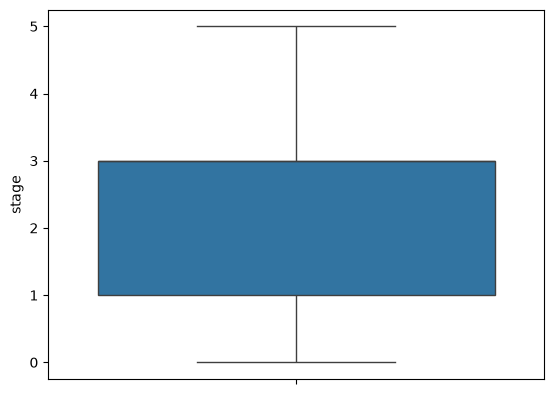

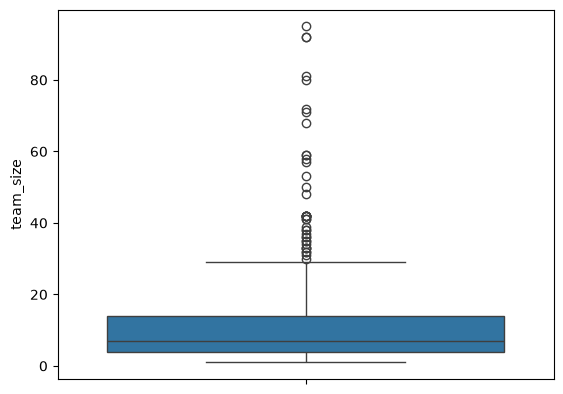

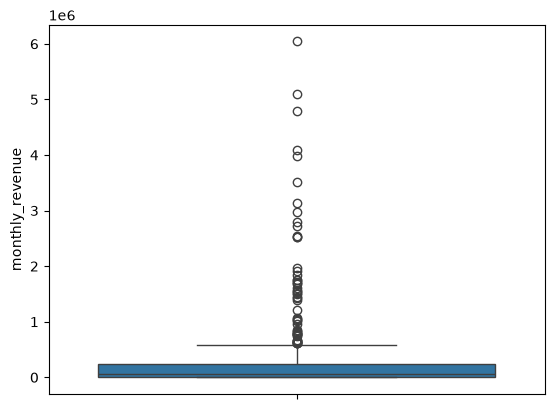

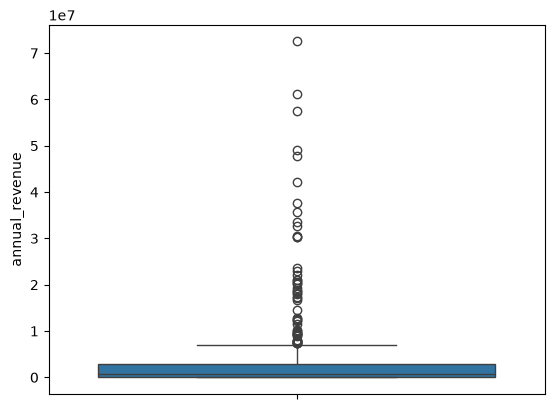

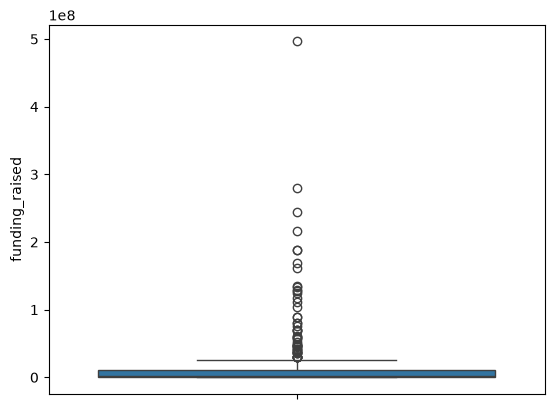

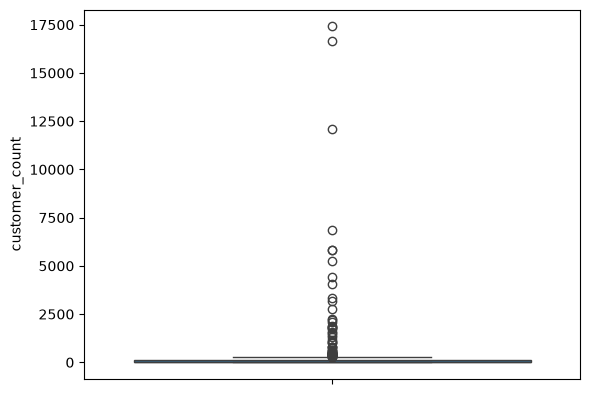

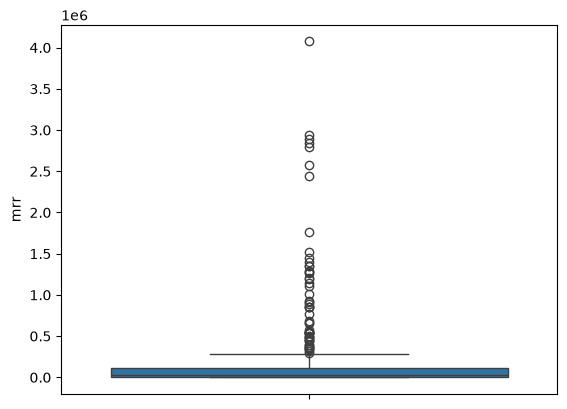

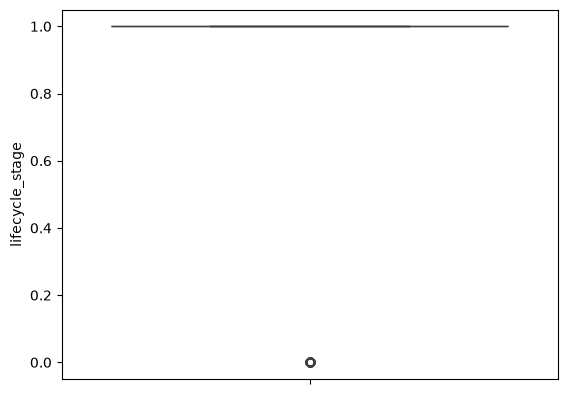

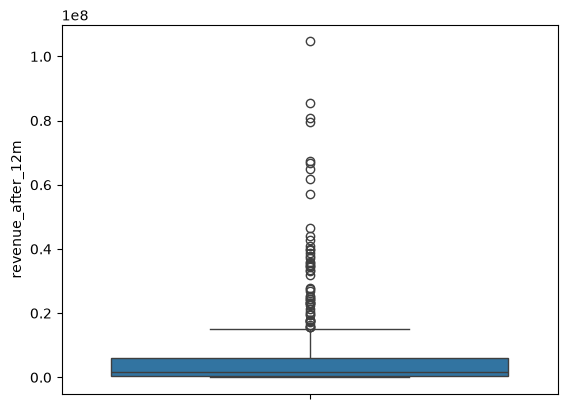

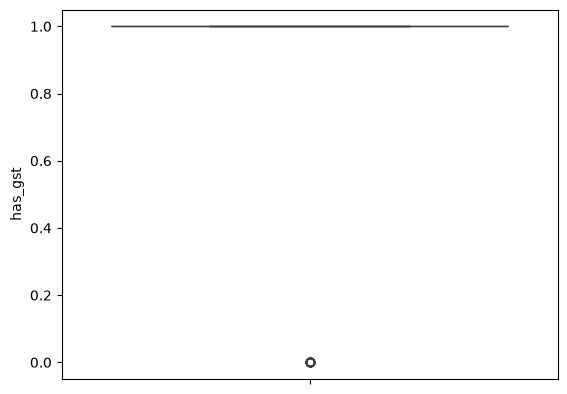

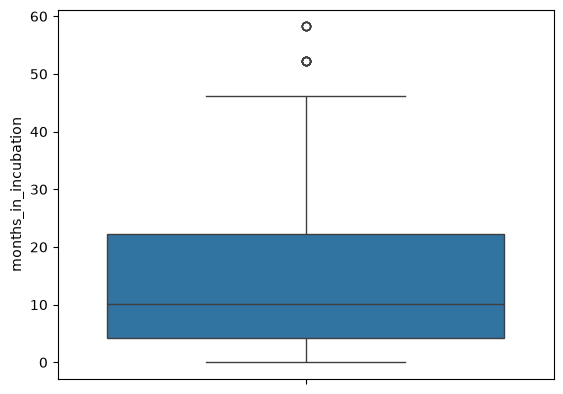

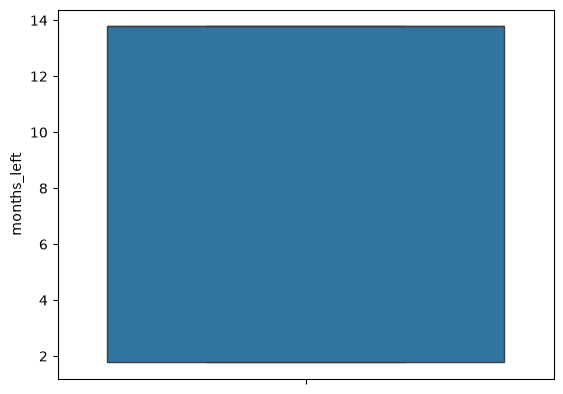

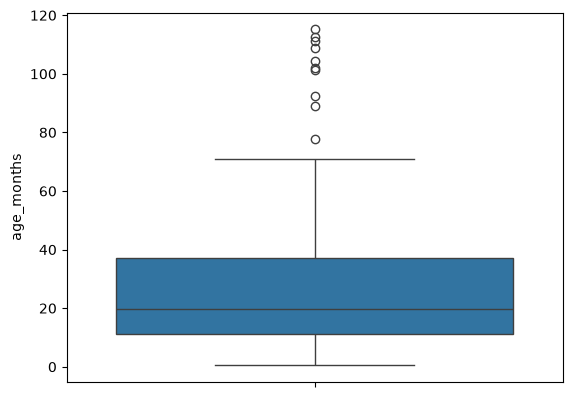

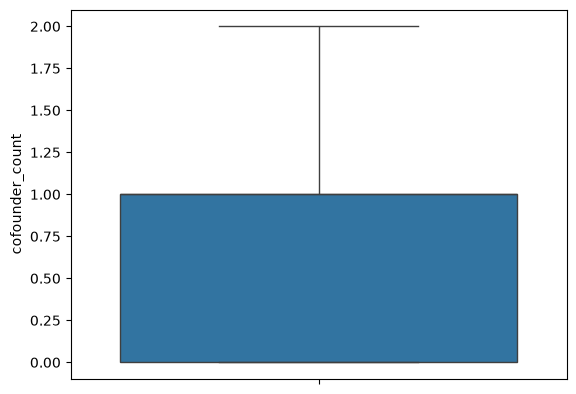

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

for i in model_num_cols:
  sns.boxplot(df[i])
  plt.show()

In [31]:
df[df['team_size'] > 40][['stage', 'team_size', 'annual_revenue', 'funding_raised']].sort_values('team_size')

,stage,team_size,annual_revenue,funding_raised
183,4,41,4560000,24550000
357,4,41,12540000,41800000
180,4,42,4260000,0
124,4,42,6540000,9550000
275,4,42,3060000,50000000
201,4,42,18600000,20800000
289,4,42,5640000,22500000
114,4,42,9480000,22500000
390,5,42,12300000,75250000
43,5,48,30480000,69800000


the outliers are not actually outliers those can be real

In [32]:
#split the data

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

log_cols = ['team_size', 'annual_revenue', 'funding_raised', 'customer_count', 'mrr']   # log + scale
num_cols = ['stage', 'lifecycle_stage', 'has_gst', 'months_in_incubation',
            'months_left', 'age_months', 'cofounder_count']                              # sirf scale
cat_cols = ['sector', 'buisness_group', 'revenue_model', 'registration_type']

X = df[log_cols + num_cols + cat_cols]          # independent columns
y = np.log1p(df['revenue_after_12m'])

In [33]:
df['revenue_model'].unique()

<ArrowStringArray>
['Fees', 'Subscription', 'Commission', 'Sales']
Length: 4, dtype: str

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=df['stage'])

print(len(X_train),len(X_test),len(y_train),len(y_test))

320 80 320 80


In [35]:
preprocessor=ColumnTransformer([
    ('log', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                      ('scale', StandardScaler())]), log_cols),
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

In [36]:
def make_pipe(model):
    return Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

In [37]:
preprocessor

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['team_size', 'annual_revenue',
                                  'funding_raised', 'customer_count', 'mrr']),
                                ('num', StandardScaler(),
                                 ['stage', 'lifecycle_stage', 'has_gst',
                                  'months_in_incubation', 'months_left',
                                  'age_months', 'cofounder_count']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sector', 'buisness_group', 'revenue_model',
                                  'registration_type'])])

In [38]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'ElasticNet': ElasticNet(),

    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=200, random_state=42),

    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),

    'SVR': SVR(),
    'KNN': KNeighborsRegressor()
}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():

    pipe = make_pipe(model)

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )

    results.append({
        'Model': name,
        'RMSE': -scores['test_score'].mean(),
        'Std': scores['test_score'].std()
    })

results_df = pd.DataFrame(results).sort_values('RMSE')

print(results_df)

                     Model      RMSE       Std
1                    Ridge  3.192543  0.370564
11                     KNN  3.192846  0.517155
5            Random Forest  3.216694  0.651457
0        Linear Regression  3.225558  0.379220
7        Gradient Boosting  3.244717  0.532566
9                 AdaBoost  3.286973  0.262682
3               ElasticNet  3.300402  0.325071
2                    Lasso  3.358586  0.303987
8   Hist Gradient Boosting  3.382742  0.597534
6              Extra Trees  3.482184  0.725868
10                     SVR  3.659947  0.530590
4            Decision Tree  4.281926  0.770706


In [39]:
from sklearn.dummy import DummyRegressor

dummy = make_pipe(DummyRegressor(strategy='mean'))

scores = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=kf,
    scoring='neg_root_mean_squared_error'
)

print("Dummy RMSE:", -scores['test_score'].mean())

Dummy RMSE: 5.520779188166101


In [40]:
preprocessor

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['team_size', 'annual_revenue',
                                  'funding_raised', 'customer_count', 'mrr']),
                                ('num', StandardScaler(),
                                 ['stage', 'lifecycle_stage', 'has_gst',
                                  'months_in_incubation', 'months_left',
                                  'age_months', 'cofounder_count']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sector', 'buisness_group', 'revenue_model',
                                  'registration_type'])])

In [41]:
param_grids = {

    'Ridge': {
        'model__alpha': [0.01, 0.1, 1, 10, 100, 1000],
        'model__fit_intercept': [True, False]
    },

    'Lasso': {
        'model__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10],
        'model__fit_intercept': [True, False]
    },

    'ElasticNet': {
        'model__alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10],
        'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
    },

    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10, 20],
        'model__min_samples_leaf': [1, 2, 5, 10]
    },

    'Random Forest': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [None, 5, 10, 20],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 1.0]
    },

    'Extra Trees': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [None, 5, 10, 20],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 1.0]
    },

    'Gradient Boosting': {
        'model__n_estimators': [100, 200, 300],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [2, 3, 5],
        'model__subsample': [0.8, 1.0],
        'model__min_samples_leaf': [1, 5]
    },

    'Hist Gradient Boosting': {
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_iter': [100, 200, 300],
        'model__max_depth': [None, 3, 5],
        'model__min_samples_leaf': [5, 10, 20],
        'model__l2_regularization': [0, 1]
    },

    'AdaBoost': {
        'model__n_estimators': [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 1],
        'model__loss': ['linear', 'square', 'exponential']
    },

    'SVR': {
        'model__kernel': ['rbf', 'linear'],
        'model__C': [0.1, 1, 10, 100],
        'model__epsilon': [0.01, 0.1, 0.5],
        'model__gamma': ['scale', 'auto']
    },

    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    }
}

from sklearn.model_selection import GridSearchCV

tuned_models = {}     # best trained pipelines yahan save honge
tuning_results = []

for name, grid in param_grids.items():
    print("Tuning:", name)

    gs = GridSearchCV(
        estimator=make_pipe(models[name]),
        param_grid=grid,
        cv=kf, #cross validation to divide the training data further into parts 
        scoring='neg_root_mean_squared_error', #thsi tells grid search cv how to evalaute the model
        n_jobs=-1,
        refit=True
    )
    gs.fit(X_train, y_train)

    tuned_models[name] = gs.best_estimator_
    tuning_results.append({
        'Model': name,
        'Best CV RMSE': -gs.best_score_,
        'Best Params': gs.best_params_
    })

tuning_df = pd.DataFrame(tuning_results).sort_values('Best CV RMSE')
pd.set_option('display.max_colwidth', None)
tuning_df

Tuning: Ridge
Tuning: Lasso
Tuning: ElasticNet
Tuning: Decision Tree
Tuning: Random Forest
Tuning: Extra Trees
Tuning: Gradient Boosting
Tuning: Hist Gradient Boosting
Tuning: AdaBoost
Tuning: SVR
Tuning: KNN


,Model,Best CV RMSE,Best Params
4,Random Forest,2.992569,"{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 100}"
5,Extra Trees,3.004669,"{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 100}"
10,KNN,3.017306,"{'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'uniform'}"
6,Gradient Boosting,3.054540,"{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__n_estimators': 100, 'model__subsample': 1.0}"
9,SVR,3.058803,"{'model__C': 10, 'model__epsilon': 0.5, 'model__gamma': 'scale', 'model__kernel': 'rbf'}"
8,AdaBoost,3.066556,"{'model__learning_rate': 0.01, 'model__loss': 'linear', 'model__n_estimators': 100}"
2,ElasticNet,3.118388,"{'model__alpha': 0.1, 'model__l1_ratio': 0.1}"
1,Lasso,3.123522,"{'model__alpha': 0.1, 'model__fit_intercept': True}"
0,Ridge,3.130846,"{'model__alpha': 10, 'model__fit_intercept': True}"
7,Hist Gradient Boosting,3.134610,"{'model__l2_regularization': 1, 'model__learning_rate': 0.01, 'model__max_depth': 3, 'model__max_iter': 300, 'model__min_samples_leaf': 20}"



- Lower RMSE = Better predictions.
- Higher RMSE = Larger prediction errors.

In [42]:
tuning_df.iloc[0]['Model']

'Random Forest'

In [43]:
tuned_models

{'Ridge': Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('log',
                                                   Pipeline(steps=[('log',
                                                                    FunctionTransformer(feature_names_out='one-to-one',
                                                                                        func=<ufunc 'log1p'>)),
                                                                   ('scale',
                                                                    StandardScaler())]),
                                                   ['team_size',
                                                    'annual_revenue',
                                                    'funding_raised',
                                                    'customer_count', 'mrr']),
                                                  ('num', StandardScaler(),
                                                   ['stage', 'lifecycle_st

In [44]:
best_model_name = tuning_df.iloc[0]['Model']

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)
print("Best Parameters:", best_model.named_steps['model'].get_params())

Best Model: Random Forest
Best Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [45]:
best_model

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('log',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['team_size',
                                                   'annual_revenue',
                                                   'funding_raised',
                                                   'customer_count', 'mrr']),
                                                 ('num', StandardScaler(),
                                                  ['stage', 'lifecycle_stage',
                                                   'has_gst',
                                                   'months_in_incubation',
                                                   'months_left', 'age_months',
                                                   'cofounder_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sector', 'buisness_group',
                                                   'revenue_model',
                                                   'registration_type'])])),
                ('model',
                 RandomForestRegressor(max_depth=10, max_features='sqrt',
                                       min_samples_leaf=2, min_samples_split=10,
                                       random_state=42))])

In [46]:
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error

y_pred = best_model.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R2:",r2)

Test RMSE: 2.790794179336426
Test R2: 0.7376417238265225


In [47]:
import numpy as np

# Convert back to original scale
y_actual = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

# Calculate percentage error
percentage_error = np.abs(
    (y_actual - y_pred_original) / np.maximum(np.abs(y_actual), 1e-10)
)

# Accuracy within 10% tolerance
tolerance = 0.10

accuracy = np.mean(percentage_error <= tolerance) * 100

print(f"Accuracy within 10% tolerance: {accuracy:.2f}%")

Accuracy within 10% tolerance: 6.25%


In [48]:
percentage_error

309    0.321569
379    1.602422
239    0.132007
203    0.149868
296    0.731244
         ...   
20     0.305476
181    0.251591
377    0.400537
247    0.968014
26     0.277099
Name: revenue_after_12m, Length: 80, dtype: float64

In [49]:
print(X_train.columns)

Index(['team_size', 'annual_revenue', 'funding_raised', 'customer_count',
       'mrr', 'stage', 'lifecycle_stage', 'has_gst', 'months_in_incubation',
       'months_left', 'age_months', 'cofounder_count', 'sector',
       'buisness_group', 'revenue_model', 'registration_type'],
      dtype='str')


In [50]:
X_train.head(2)

,team_size,annual_revenue,funding_raised,customer_count,mrr,stage,lifecycle_stage,has_gst,months_in_incubation,months_left,age_months,cofounder_count,sector,buisness_group,revenue_model,registration_type
207,30,12180000,4550000,262,849000,4,1,1,10.197368,1.776316,32.532895,1,Cybersecurity,B2B,Subscription,Private Limited
172,2,0,400000,0,0,1,1,1,16.250000,1.776316,13.651316,1,EdTech,Mixed,Subscription,Private Limited


In [51]:
# 100,200,40,500
# sample_split 2,5
# min_samples_leaf 10,2

# 200 + 5 +

In [52]:
# import numpy as np, pandas as pd
# from sklearn.base import clone
# from sklearn.model_selection import GridSearchCV

# # ---------- 1) data se maximum limits ----------
# n_fold = int(len(X_train) * (kf.get_n_splits() - 1) / kf.get_n_splits())                 # ek fold ke train rows
# n_feat = make_pipe(models['Ridge']).named_steps['prep'].fit_transform(X_train).shape[1]  # one-hot ke baad columns

# STEP  = 1                                   # 1 karoge to har number try hoga (slow)
# trees = list(range(5, 801, STEP))           # 5 se 800 tak
# depth = [None] + list(range(1, 101))        # 1 se 100 tak, ya bina limit
# split = list(range(2, n_fold + 1))
# leaf  = list(range(1, n_fold // 2 + 1))
# feat  = list(range(1, n_feat + 1)) + [0.3, 0.5, 0.8, 1.0, 'sqrt', 'log2']
# lr    = list(np.round(np.logspace(np.log10(0.001), np.log10(1.0), 20), 4))

# # ---------- 2) har model ki ranges ----------
# param_ranges = {
#  'Ridge':      {'alpha': list(np.logspace(-6, 4, 101)), 'fit_intercept': [True, False]},
#  'Lasso':      {'alpha': list(np.logspace(-6, 2,101)), 'fit_intercept': [True, False]},
#  'ElasticNet': {'alpha': list(np.logspace(-6, 2, 101)),
#                 'l1_ratio': list(np.round(np.arange(0.01, 1.0, 0.01), 2))},
#  'Decision Tree': {'max_depth': depth, 'min_samples_split': split, 'min_samples_leaf': leaf},
#  'Random Forest': {'n_estimators': trees, 'max_depth': depth, 'min_samples_split': split,
#                    'min_samples_leaf': leaf, 'max_features': feat},
#  'Extra Trees':   {'n_estimators': trees, 'max_depth': depth, 'min_samples_split': split,
#                    'min_samples_leaf': leaf, 'max_features': feat},
#  'Gradient Boosting': {'n_estimators': trees, 'learning_rate': lr, 'max_depth': list(range(1, 31)),
#                        'subsample': list(np.round(np.arange(0.1, 1.01, 0.05), 2)),
#                        'min_samples_leaf': leaf},
#  'Hist Gradient Boosting': {'max_iter': trees, 'learning_rate': lr,
#                             'max_depth': [None] + list(range(2, 31)),
#                             'min_samples_leaf': list(range(2, n_fold // 2 + 1)),
#                             'l2_regularization': [0] + list(np.logspace(-4, 2, 15))},
#  'AdaBoost': {'n_estimators': trees, 'learning_rate': list(np.round(np.logspace(-3, 0.5, 20), 4)),
#               'loss': ['linear', 'square', 'exponential']},
#  'SVR': {'kernel': ['rbf', 'linear'], 'C': list(np.logspace(-3, 4, 30)),
#          'epsilon': list(np.logspace(-3, 0.5, 20)), 'gamma': ['scale', 'auto']},
#  'KNN': {'n_neighbors': list(range(1, n_fold + 1)), 'weights': ['uniform', 'distance'], 'p': [1, 2]}}

# # ---------- 3) ek-ek setting ko GridSearchCV se tune karo; jab tak sudhar aaye tab tak rounds ----------
# def tune_one_by_one(base_model, ranges, max_rounds=10, tol=0.02):
#     best_params, best_score = {}, float('inf')
#     for r in range(max_rounds):
#         score_before = best_score                                   # round shuru hone se pehle ka score
#         for param, values in ranges.items():
#             model = clone(base_model).set_params(**best_params)      # ab tak ki best settings fix
#             gs = GridSearchCV(make_pipe(model), {f'model__{param}': values},
#                               cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
#             gs.fit(X_train, y_train)
#             new_score = -gs.best_score_
#             if param not in best_params or new_score < best_score - tol:   # sach me behtar ho tabhi badlo
#                 best_params[param] = gs.best_params_[f'model__{param}']
#                 best_score = new_score
#         print('  Round', r + 1, '| CV RMSE:', round(best_score, 4))
#         if r > 0 and score_before - best_score < tol:               # is round me koi sudhar nahi
#             print('  Is round me sudhar nahi hua, ruk gaye.')
#             break
#     return best_params, best_score

# # ---------- 4) saare models tune karo ----------
# tuned_models, tuning_results = {}, []
# for name, ranges in param_ranges.items():
#     print("Tuning:", name)
#     bp, bs = tune_one_by_one(models[name], ranges, max_rounds=10)
#     tuned_models[name] = clone(make_pipe(clone(models[name]).set_params(**bp))).fit(X_train, y_train)
#     tuning_results.append({'Model': name, 'Best CV RMSE': bs, 'Best Params': bp})

# tuning_df = pd.DataFrame(tuning_results).sort_values('Best CV RMSE').reset_index(drop=True)
# pd.set_option('display.max_colwidth', None)

# # ---------- 5) check: best value range ke kinaare pe to nahi? ----------
# natural_limits = {'min_samples_split': 2, 'min_samples_leaf': 1, 'subsample': 1.0,
#                   'l1_ratio': 0.01, 'max_depth': 1}              # in values ke aage jaana mumkin nahi
# skip_params = {'p', 'fit_intercept', 'weights', 'loss', 'kernel', 'gamma'}
# for name, ranges in param_ranges.items():
#     bp = tuning_df.loc[tuning_df['Model'] == name, 'Best Params'].iloc[0]
#     for p, v in bp.items():
#         if p in skip_params or p not in ranges:
#             continue
#         vals = ranges[p]
#         is_number = isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool)
#         if is_number and v in (vals[0], vals[-1]) and v != natural_limits.get(p):
#             print(f"{name}: '{p}' = {v} range ke kinaare pe hai, range badha ke dekho")
# print("Check done")

# tuning_df

In [53]:
# tuning_df.iloc[0]

In [54]:
# best_model_name = tuning_df.iloc[0]['Model']

# best_model = tuned_models[best_model_name]

# print("Best Model:", best_model_name)
# print("Best Parameters:", best_model.named_steps['model'].get_params())

In [55]:
# best_model

In [56]:

# y_pred = best_model.predict(X_test)

# rmse = root_mean_squared_error(y_test, y_pred)
# r2 = r2_score(y_test, y_pred)

# print("Test RMSE:", rmse)
# print("Test R2:",r2)

In [57]:
# import numpy as np

# # Convert back to original scale
# y_actual = np.expm1(y_test)
# y_pred_original = np.expm1(y_pred)

# # Calculate percentage error
# percentage_error = np.abs(
#     (y_actual - y_pred_original) / np.maximum(np.abs(y_actual), 1e-10)
# )

# # Accuracy within 10% tolerance
# tolerance = 0.10

# accuracy = np.mean(percentage_error <= tolerance) * 100

# print(f"Accuracy within 10% tolerance: {accuracy:.2f}%")

In [58]:
make_pipe

<function __main__.make_pipe(model)>

In [59]:
preprocessor

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['team_size', 'annual_revenue',
                                  'funding_raised', 'customer_count', 'mrr']),
                                ('num', StandardScaler(),
                                 ['stage', 'lifecycle_stage', 'has_gst',
                                  'months_in_incubation', 'months_left',
                                  'age_months', 'cofounder_count']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sector', 'buisness_group', 'revenue_model',
                                  'registration_type'])])

In [60]:

param_grids = {

    # RANDOM FOREST

# RANDOM FOREST
'Random Forest': {
    'model__n_estimators': [10, 18, 30, 50, 100],
    'model__max_depth': [3, 4, 5, 8, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [20, 29, 35, 'sqrt'],
    'model__criterion': ['squared_error', 'friedman_mse'],
    'model__bootstrap': [True, False],
    'model__max_leaf_nodes': [None, 30, 50]
},

# EXTRA TREES
'Extra Trees': {
    'model__n_estimators': [6, 10, 20, 50, 100],
    'model__max_depth': [3, 4, 5, 7, None],
    'model__min_samples_split': [2, 10, 20, 32],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [25, 30, 38, 'sqrt'],
    'model__criterion': ['squared_error', 'friedman_mse'],
    'model__bootstrap': [True, False],
    'model__max_leaf_nodes': [None, 30, 50]
}
,

    # KNN
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 8, 9, 11, 13, 15, 17, 20, 25, 30],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },

    # RIDGE
    'Ridge': {
        'model__alpha': [
            0.1, 0.5, 1, 5, 10, 20, 31.62, 50, 75, 100, 
        ],
        'model__fit_intercept': [True, False]
    },

    # GRADIENT BOOSTING
    'Gradient Boosting': {
        'model__n_estimators': [20, 30, 43, 50, 60, 75, 100, 150, 200],
        'model__learning_rate': [0.01, 0.02, 0.03, 0.05, 0.0785, 0.1, 0.15, 0.2],
        'model__max_depth': [1, 2, 3, 4, 5],
        'model__subsample': [0.7, 0.8, 0.9, 0.95, 1.0],
        'model__min_samples_leaf': [1, 2, 3, 4, 5, 10],
        'model__max_features': [None, 'sqrt', 'log2']
    }
}


In [ ]:

models = {
    'Random Forest': RandomForestRegressor(),
    'Extra Trees': ExtraTreesRegressor(),
    'KNN': KNeighborsRegressor(),
    'Ridge': Ridge(),
    'Gradient Boosting': GradientBoostingRegressor()
}

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import pandas as pd

tuned_models = {}
tuning_results = []

for name, model in models.items():

    print("\nTuning:", name)

    # Remove 'model__' because GridSearchCV is directly
    # tuning the model inside the Pipeline
    grid_params = {
        key.replace('model__', ''): value
        for key, value in param_grids[name].items()
    }

    grid = GridSearchCV(
        estimator=model,
        param_grid=grid_params,
        cv=kf,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", grid)
    ])

    pipe.fit(X_train, y_train)

    # Store best fitted pipeline
    tuned_models[name] = pipe

    tuning_results.append({
        'Model': name,
        'Best CV RMSE': -grid.best_score_,
        'Best Params': grid.best_params_
    })


# RESULTS

tuning_df = (
    pd.DataFrame(tuning_results)
    .sort_values('Best CV RMSE')
    .reset_index(drop=True)
)

pd.set_option('display.max_colwidth', None)

tuning_df


Tuning: Random Forest
Fitting 5 folds for each of 14400 candidates, totalling 72000 fits

Tuning: Extra Trees
Fitting 5 folds for each of 14400 candidates, totalling 72000 fits

Tuning: KNN
Fitting 5 folds for each of 48 candidates, totalling 240 fits

Tuning: Ridge
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Tuning: Gradient Boosting
Fitting 5 folds for each of 32400 candidates, totalling 162000 fits


,Model,Best CV RMSE,Best Params
0,Extra Trees,2.862416,"{'model__bootstrap': False, 'model__criterion': 'squared_error', 'model__max_depth': 3, 'model__max_features': 38, 'model__max_leaf_nodes': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 32, 'model__n_estimators': 6}"
1,Gradient Boosting,2.941603,"{'model__learning_rate': 0.0785, 'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 75, 'model__subsample': 1.0}"
2,Random Forest,2.947422,"{'model__bootstrap': True, 'model__criterion': 'squared_error', 'model__max_depth': 4, 'model__max_features': 29, 'model__max_leaf_nodes': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 18}"
3,KNN,3.001419,"{'model__n_neighbors': 8, 'model__p': 1, 'model__weights': 'uniform'}"
4,Ridge,3.117854,"{'model__alpha': 31.62, 'model__fit_intercept': True}"


In [63]:
param_grids = {

    # RANDOM FOREST
    'Random Forest': {
        'model__n_estimators': [6, 10, 18, 20, 40, 50, 80],
        'model__max_depth': [2, 3, 4, 5, 6, 10, 12, None],
        'model__min_samples_split': [2, 3, 4, 5, 8, 9, 10, 15, 20],
        'model__min_samples_leaf': [1, 2, 3, 4],
        'model__max_features': [20, 25, 29, 35, 'sqrt', 'log2'],
        'model__criterion': ['squared_error', 'friedman_mse'],
        'model__bootstrap': [True, False],
        'model__max_leaf_nodes': [None, 20, 30, 50]
    },

    # EXTRA TREES
    'Extra Trees': {
        'model__n_estimators': [6, 10, 15, 20, 30, 50, 75, 100],
        'model__max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
        'model__min_samples_split': [2, 5, 10, 15, 20, 25, 32, 40],
        'model__min_samples_leaf': [1, 2, 3, 4],
        'model__max_features': [25, 30, 38, 45, 'sqrt', 'log2'],
        'model__criterion': ['squared_error', 'friedman_mse'],
        'model__bootstrap': [True, False],
        'model__max_leaf_nodes': [None, 20, 30, 50]
    },

    # KNN
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 8, 9, 11, 13, 15, 17, 20, 25, 30],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },

    # RIDGE
    'Ridge': {
        'model__alpha': [
            0.1, 0.5, 1, 5, 10, 20, 31.62, 50, 75, 100, 200, 300
        ],
        'model__fit_intercept': [True, False]
    },

    # GRADIENT BOOSTING
    'Gradient Boosting': {
        'model__n_estimators': [20, 30, 43, 50, 60, 75, 100],
        'model__learning_rate': [0.01, 0.02, 0.03, 0.05, 0.0785, 0.1, 0.15, 0.2],
        'model__max_depth': [1, 2, 3, 4, 5],
        'model__subsample': [0.7, 0.8, 0.9, 0.95, 1.0],
        'model__min_samples_leaf': [1, 2, 3, 4, 5, 10],
        'model__max_features': [None, 'sqrt', 'log2']
    }
}

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Previous best parameters
starting_params = {

    'Random Forest': {
        'n_estimators': 18,
        'max_depth': 4,
        'min_samples_split': 2,
        'min_samples_leaf': 1,
        'max_features': 29
    },

    'Extra Trees': {
        'n_estimators': 6,
        'max_depth': 3,
        'min_samples_split': 32,
        'min_samples_leaf': 1,
        'max_features': 38
    },

    'KNN': {
        'n_neighbors': 8,
        'weights': 'uniform',
        'p': 1
    },

    'Ridge': {
        'alpha': 31.622776601683793,
        'fit_intercept': True
    },

    'Gradient Boosting': {
        'n_estimators': 43,
        'learning_rate': 0.0785,
        'max_depth': 3,
        'subsample': 0.95,
        'min_samples_leaf': 1
    }
}

tuned_models = {}
tuning_results = []

for name, grid in param_grids.items():

    print("\nTuning:", name)

    # Start with previously tuned best parameters
    base_model = clone(models[name]).set_params(
        **starting_params[name]
    )

    gs = GridSearchCV(
        estimator=make_pipe(base_model),
        param_grid=grid,
        cv=kf,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    gs.fit(X_train, y_train)

    tuned_models[name] = gs.best_estimator_

    tuning_results.append({
        'Model': name,
        'Best CV RMSE': -gs.best_score_,
        'Best Params': gs.best_params_
    })

tuning_df = (
    pd.DataFrame(tuning_results)
    .sort_values('Best CV RMSE')
    .reset_index(drop=True)
)

pd.set_option('display.max_colwidth', None)
tuning_df



Tuning: Random Forest
Fitting 5 folds for each of 193536 candidates, totalling 967680 fits

Tuning: Extra Trees
Fitting 5 folds for each of 221184 candidates, totalling 1105920 fits

Tuning: KNN
Fitting 5 folds for each of 48 candidates, totalling 240 fits

Tuning: Ridge
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Tuning: Gradient Boosting
Fitting 5 folds for each of 25200 candidates, totalling 126000 fits


,Model,Best CV RMSE,Best Params
0,Extra Trees,2.862416,"{'model__bootstrap': False, 'model__criterion': 'squared_error', 'model__max_depth': 3, 'model__max_features': 38, 'model__max_leaf_nodes': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 32, 'model__n_estimators': 6}"
1,Random Forest,2.929466,"{'model__bootstrap': False, 'model__criterion': 'squared_error', 'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__max_leaf_nodes': None, 'model__min_samples_leaf': 3, 'model__min_samples_split': 10, 'model__n_estimators': 6}"
2,Gradient Boosting,2.941603,"{'model__learning_rate': 0.0785, 'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 75, 'model__subsample': 1.0}"
3,KNN,3.001419,"{'model__n_neighbors': 8, 'model__p': 1, 'model__weights': 'uniform'}"
4,Ridge,3.117854,"{'model__alpha': 31.62, 'model__fit_intercept': True}"


In [62]:
df.head(2)

,startup_name,tagline_pitch,description,sector,stage,team_size,problem_statement,solution_description,target_market,business_model,revenue_model,registration_type,monthly_revenue,annual_revenue,funding_raised,customer_count,mrr,lifecycle_stage,revenue_after_12m,has_gst,months_in_incubation,months_left,age_months,cofounder_count,buisness_group
0,Neem Freight,Faster and cheaper local deliveries,A last-mile delivery network for small online sellers.,Logistics,0,2,Small sellers pay high shipping costs and face late deliveries.,The platform pools orders from many sellers and assigns them to local delivery partners using route planning. Sellers track every parcel in one dashboard. Support is offered over WhatsApp.,Small online sellers and local stores,B2B logistics platform,Fees,Not registered,0,0,0,0,0,0,0,0,0.000000,13.782895,4.703947,1,B2B
1,KiranHub,One place to run your small team,A project and task management tool for small teams.,SaaS,3,9,"Small teams lose track of work across chats, emails and sheets.","Teams manage tasks, deadlines and files in one place with simple boards. Reports show who is overloaded and what is delayed. Support is offered over WhatsApp. It supports regional languages.",Small companies and agencies,B2B SaaS,Subscription,LLP,115000,1380000,21200000,13,104000,1,3882000,1,34.243421,1.776316,22.532895,1,B2B
